C:\Users\Lenovo\anaconda3\Lib\site-packages\librosa\core\pitch.py:101: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(


Finished feature extraction from  920  files


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 11, 861, 16)    │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 11, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 11, 430, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 10, 429, 32)    │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 10, 214, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 10, 214, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 9, 213, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 9, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 9, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,416 (40.69 KB)

 Trainable params: 10,416 (40.69 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
[0]	validation_0-mlogloss:1.67893
[1]	validation_0-mlogloss:1.58343
[2]	validation_0-mlogloss:1.49973
[3]	validation_0-mlogloss:1.42459
[4]	validation_0-mlogloss:1.35678
[5]	validation_0-mlogloss:1.29701
[6]	validation_0-mlogloss:1.24128
[7]	validation_0-mlogloss:1.18989
[8]	validation_0-mlogloss:1.14085
[9]	validation_0-mlogloss:1.09829
[10]	validation_0-mlogloss:1.05842
[11]	validation_0-mlogloss:1.02098
[12]	validation_0-mlogloss:0.98546
[13]	validation_0-mlogloss:0.95328
[14]	validation_0-mlogloss:0.92354
[15]	validation_0-mlogloss:0.89661
[16]	validation_0-mlogloss:0.87194
[17]	validation_0-mlogloss:0.84777
[18]	validation_0-mlogloss:0.82360
[19]	validation_0-mlogloss:0.80226
[20]	validation_0-mlogloss:0.78234
[21]	validation_0-mlogloss:0.76465
[22]	validation_0-mlogloss:0.74746
[23]	validation_0-mlogloss:0.73037
[24]	validation_0-mlogloss:0.71366
[25]	validation_0-mlogloss:0.69964
[26]	validation_0-mlog

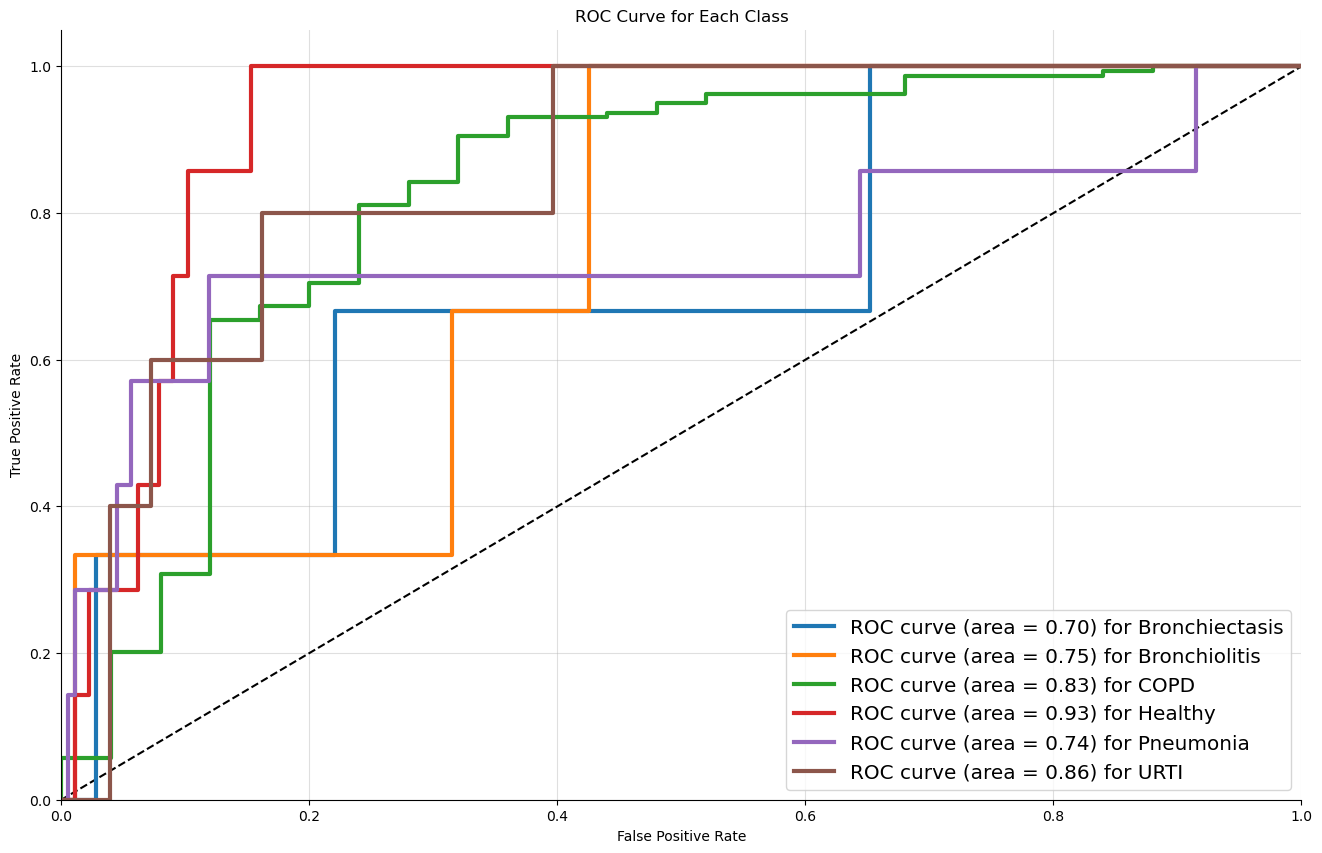

In [5]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
from datetime import datetime
from os import listdir
from os.path import isfile, join
import librosa
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# File paths and loading data
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function using Chroma Features
def extract_features(file_name):
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        
        # Check if the audio signal is valid (non-silent)
        if np.all(audio == 0):
            print(f"Warning: Silent audio file: {file_name}")
            return None
        
        # Compute Chroma Features
        chroma = librosa.feature.chroma_stft(y=audio, sr=sample_rate, n_chroma=12)
        
        # Pad or truncate to ensure consistent feature size
        pad_width = max_pad_len - chroma.shape[1]
        chroma = np.pad(chroma, pad_width=((0, 0), (0, pad_width)), mode='constant')
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None
    return chroma

# Full paths of files
filepaths = [join(mypath, f) for f in filenames]

# Load patient diagnosis file
p_diag = pd.read_csv("E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database/patient_diagnosis.csv", header=None)

# Labels for audio files
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])

# Extract features
features = []
for file_name in filepaths:
    data = extract_features(file_name)
    if data is not None:
        features.append(data)

print('Finished feature extraction from ', len(features), ' files')
features = np.array(features)  # Shape: (num_files, num_chroma_bins, max_pad_len)

# Removing specific labels and converting labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Reshape features for CNN
features1 = np.reshape(features1, (*features1.shape, 1))  # Add channel dimension

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction
num_rows = 12  # Number of Chroma bins
num_columns = max_pad_len  # Time steps
num_channels = 1  # Single channel
filter_size = (2, 2)  # Smaller kernel size

cnn_model = Sequential()
cnn_model.add(Input(shape=(num_rows, num_columns, num_channels)))
cnn_model.add(Conv2D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=(1, 2)))  # Pool only along the time axis
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=(1, 2)))  # Pool only along the time axis
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=(1, 2)))  # Pool only along the time axis
cnn_model.add(Dropout(0.2))
cnn_model.add(GlobalAveragePooling2D())

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Flatten the features for XGBoost
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Convert one-hot labels to single integers for XGBoost
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# XGBoost model
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    early_stopping_rounds=10
)

# Train the XGBoost model
xgb_model.fit(x_train_features, y_train, eval_set=[(x_test_features, y_test)], verbose=True)

# Evaluate model
y_pred = xgb_model.predict(x_test_features)
accuracy = accuracy_score(y_test, y_pred)
print(f"XGBoost Test Accuracy: {accuracy:.4f}")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = xgb_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()